# Visualización P2 sobre el notebook de Jeffrey

Se reutiliza `draw_pitch` y el flujo `clear_output → display → delay` de [agente_cero_mc_control_persecucion.ipynb](https://github.com/jeffreymonjacastro/grupo-02-proyecto-rl/blob/172f5523910c3be0bf537c9a57f26120aa6ec95f/notebooks/agente_cero_mc_control_persecucion.ipynb).
El dibujo conserva el estilo de P1, con encuadre ampliado para ver el arco.

Aquí los movimientos proceden del **servidor oficial**, ejecutando modelos P2 congelados. No se usa el simulador cinemático de P1 ni un panel independiente.

Ejecuta las celdas en orden con el kernel **RoboCup P2 (CUDA)**. Los cambios de escenario son pruebas intervenidas: no representan resultados del benchmark.

## 1. Preparar el entorno

In [1]:
%matplotlib inline
from pathlib import Path
import os

ROOT = Path.cwd()
if not (ROOT / 'pyproject.toml').exists():
    ROOT = ROOT.parent
assert (ROOT / 'pyproject.toml').exists(), 'Abre el notebook desde la carpeta del proyecto'
os.chdir(ROOT)
from robocup_rl.demo_jeffrey import animar_politica
import torch
assert torch.cuda.is_available(), 'Esta demostración usa CUDA'
print('GPU:', torch.cuda.get_device_name(0))

GPU: NVIDIA GeForce RTX 4080


## 2. Elegir qué política observar

`tarea`: `persecucion`, `conduccion`, `definicion`, `global` o `plana`.
`algoritmo`: `ppo`, `a2c` o `dqn`. La jerarquía carga también sus tres habilidades.
Los modelos disponibles fueron entrenados en `2v1`; seleccionar `1v1` requiere pesos de ese escenario.

In [2]:
TAREA = 'persecucion'
ALGORITMO = 'ppo'
SEMILLA = 0
ESCENARIO = '2v1'
PASOS = 40
CADA = 2               # dibujar cada dos ciclos físicos
DELAY = 0.06
PASO_A_PASO = False    # True: Enter avanza; q termina y cierra el servidor

## 3. Objetivos y escenario inicial

Para persecución, el objetivo aprendido es capturar el balón: cambia su posición o velocidad.
En conducción, el objetivo aprendido es avanzar hasta la zona de ataque; en definición es marcar gol.
`ZONA` permite medir una región adicional `[x, y, radio]` y dibujarla, pero la red no recibe esa meta ni se reentrena al cambiarla.

Unidades: metros y velocidad por ciclo físico del servidor. x crece hacia el arco rival. Ajusta las posiciones a la subtarea: para definición coloca atacante y balón cerca de x=38.

In [3]:
INICIAL = {
    'posiciones': {
        'atacante': [-10, 0],
        'balon': [0, 0],
        'defensor': [23, 3],
        'arquero': [50, 0],
    },
    'velocidad_balon': [0.15, -0.08],
    'condiciones': {
        'defensor': 'perseguir',  # perseguir / patrulla / quieto
        'potencia_defensor': 100,
        'arquero_activo': True,
    },
}
ZONA = [5, -5, 3]      # None para no mostrar una zona adicional

## 4. Cambiar el entorno durante la ejecución

Las claves son ciclos físicos (desde 0). Puedes mover objetos, cambiar la velocidad del balón o la conducta de los rivales. Para una escena fija usa `CAMBIOS = {}`.
Si el episodio termina antes de un cambio programado, ese cambio no llega a ejecutarse.

In [4]:
CAMBIOS = {
    6: {
        'posiciones': {'balon': [4, -5]},
        'velocidad_balon': [0.4, 0.2],
        'condiciones': {'defensor': 'patrulla', 'potencia_defensor': 60},
    },
    25: {
        'posiciones': {'defensor': [15, 2]},
        'condiciones': {'defensor': 'perseguir', 'potencia_defensor': 100},
    },
}

## 5. Reproducir la animación

Como en P1, esta celda actualiza el campo en su propia salida. `PASO_A_PASO=True` congela el servidor mientras eliges avanzar. Al acabar se conserva el último frame y se cierra el servidor.

Para comparar otra política, cambia las variables y vuelve a ejecutar esta celda. El puerto 6500 está separado del entrenamiento/evaluación (6200).

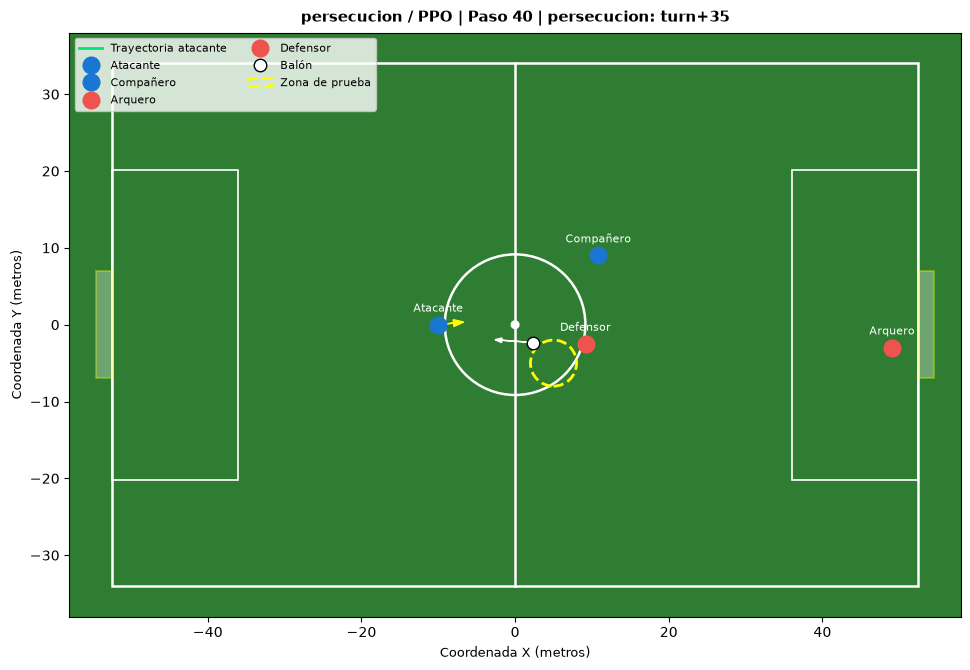

{'pasos': 40, 'exito_tarea': False, 'gol': False, 'zona_visitada': True, 'salida': 'runs\\demo_jeffrey\\persecucion_ppo_seed_0', 'tipo': 'demostración; no evaluación de rendimiento'}


In [5]:
resultado = animar_politica(
    tarea=TAREA, algoritmo=ALGORITMO, semilla=SEMILLA, escenario=ESCENARIO,
    inicial=INICIAL, cambios=CAMBIOS, zona=ZONA,
    pasos=PASOS, cada=CADA, delay=DELAY, paso_a_paso=PASO_A_PASO,
    puerto=6500, salida=f'runs/demo_jeffrey/{TAREA}_{ALGORITMO}_seed_{SEMILLA}',
)
print(resultado)

## 6. Repetir y revisar

Los parámetros y la trayectoria quedan en `runs/demo_jeffrey/`, separados de la evaluación oficial. `ultimo_frame.png` conserva el último campo dibujado.

Para observar definición: `TAREA='definicion'`, atacante `[38,0]`, balón `[38.5,0]`, defensor `[32,4]`; comienza con `CAMBIOS={}`. Para observar el ataque jerárquico usa `TAREA='global'` y las posiciones iniciales de medio campo.

Completar la animación no demuestra que el agente resuelva la tarea. La tasa de gol se consulta en evaluaciones de al menos 200 episodios sin intervenciones.